
# Project 02: Diabetes Prediction using Machine Learning

## Overview
This project focuses on predicting whether a person is likely to have diabetes using Machine Learning. It uses the Pima Indians Diabetes Dataset and implements a Logistic Regression classification model.

## Dataset
- **Source:** [Pima Indians Diabetes Dataset](https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv)
- **Total Records:** 768
- **Features:** 8 input features
- **Target Variable:** Outcome (0 = Non-Diabetic, 1 = Diabetic)

## Technologies & Libraries
- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- Joblib

## Machine Learning Workflow
1. Data Loading
2. Exploratory Data Analysis (EDA)
3. Data Cleaning and Preprocessing
4. Handling Invalid Zero Values
5. Train-Test Split (80:20)
6. Missing Value Imputation using Median
7. Feature Scaling using StandardScaler
8. Model Training using Logistic Regression
9. Model Evaluation

## Model Performance

| Metric | Score |
|---|---:|
| Accuracy | 73.38% |
| Precision | 60.32% |
| Recall | 70.37% |
| F1 Score | 64.96% |

## Project Files
- `Diabetes_Prediction.ipynb` – Complete Jupyter Notebook.
- `diabetes_prediction_model.pkl` – Saved trained ML pipeline.

## Key Learnings
- Understanding binary classification.
- Data preprocessing and handling missing values.
- Using Scikit-learn Pipelines.
- Feature scaling and Logistic Regression.
- Evaluating models using accuracy, precision, recall, F1-score and confusion matrix.

## Disclaimer
This project is developed for educational purposes only. It is not intended for clinical use or medical diagnosis.

All libraries imported successfully!!
Dataset loaded successfully!!
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
Dataset shape: (768, 9)

Column Names:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

Dataset Information:
<class 'panda

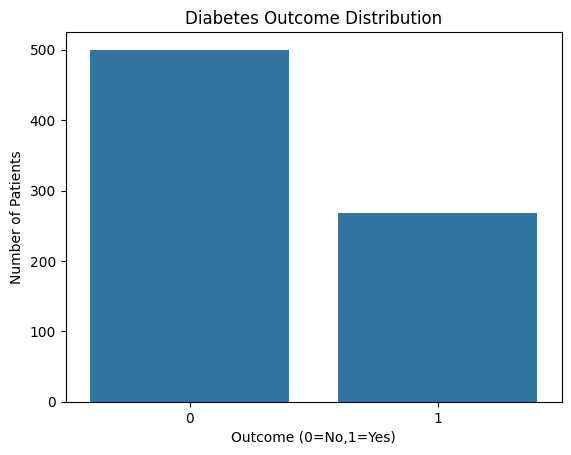

Input Features:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  
0                     0.627   50  
1                     0.351   31  
2                     0.672   32  
3                     0.167   21  
4                     2.288   33  

Target Output:
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
Training samples: 614
Testing samples: 154
Logistic Regression Model Trained Successfully!
Actual Values:
[0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0

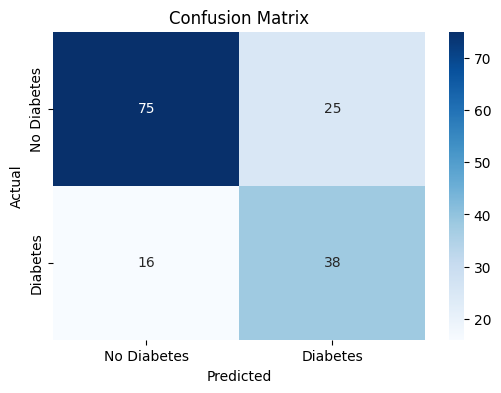

              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
#IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

print("All libraries imported successfully!!")

#LOAD THE DATASET

url="https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
df= pd.read_csv(url)
print("Dataset loaded successfully!!")

print(df.head())

#EXPLORE THE DATASET

print("Dataset shape:", df.shape)
print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

# CHECK CLASS/TARGET DISTRIBUTION

print(df['Outcome'].value_counts())
sns.countplot(x='Outcome',data=df)

plt.title("Diabetes Outcome Distribution")
plt.xlabel ("Outcome (0=No,1=Yes)")
plt.ylabel("Number of Patients")

plt.show()

#SEPARATE FEATURES AND TARGET

x=df.drop('Outcome',axis=1)
y=df['Outcome']

print("Input Features:")
print(x.head())

print("\nTarget Output:")
print(y.head())

#CHECK ZERO VALUES

columns=[
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

print(df[columns].eq(0).sum())


#SPLIT THE DATASET

x_train,x_test,y_train,y_test=train_test_split(
   x,y,test_size=0.2,
   random_state=42,
   stratify=y
)

print("Training samples:",len(x_train))
print("Testing samples:",len(x_test))

##BUILD THE ML PIPELINE AND TRAIN THE MODEL..

# HANDLE INVALID ZERO VALUES..

x_train_clean=x_train.copy()
x_test_clean=x_test.copy()

invalid_columns=[

                 'Glucose',
                 'BloodPressure',
                 'SkinThickness',
                 'Insulin',
                 'BMI'
]

x_train_clean[invalid_columns]=(
    x_train_clean[invalid_columns].replace(0,np.nan)
)

x_test_clean[invalid_columns]=(
    x_test_clean[invalid_columns].replace(0,np.nan)
)

#CREATE ML PIPELINE

model=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler()),
     ('classifier',LogisticRegression(max_iter=1000, class_weight='balanced'))
])

#TRAIN MODEL...

model.fit(x_train_clean,y_train)
print("Logistic Regression Model Trained Successfully!")

 ## STEP-9) MAKE PREDICTIONS..

y_pred=model.predict(x_test_clean)

print("Actual Values:")
print(list(y_test))

print("\nPredicted Values:")
print(list(y_pred))

##STEP-10)
 ##EVALUATE MODEL PERFORMANCE


accuracy=accuracy_score(y_test,y_pred)
precision=precision_score(y_test,y_pred)
recall=recall_score(y_test,y_pred)
f1=f1_score(y_test,y_pred)

print("Accuracy:",accuracy)
print("Precision:",precision)
print("Recall:",recall)
print("F1 Score:",f1)

## STEP-11) CONFUSION MATRIX

cm=confusion_matrix(y_test,y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes','Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()


##STEP-12 ) CLASSIFICATION REPORT

print(classification_report(y_test,y_pred))

import joblib

joblib.dump(model, 'diabetes_prediction_model.pkl')

print("Model saved successfully!")


from google.colab import files

files.download('diabetes_prediction_model.pkl')
